# 요일별 시간대별 교통사고 2025년 분석

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('../data/요일별_시간대별_교통사고-2025_KOSIS.csv', header=1)

print(df.head(10))


  요일별(1)  시간대별(1) 월별(1)  사고건수 (건)  사망자수 (명)  부상자수 (명)
0      일  00시-02시    전체      1045        23      1516
1      일  00시-02시    1월        70         0        94
2      일  00시-02시    2월        72         2       103
3      일  00시-02시    3월        88         2       133
4      일  00시-02시    4월       107         1       156
5      일  00시-02시    5월        89         1       146
6      일  00시-02시    6월       106         1       169
7      일  00시-02시    7월        78         3       111
8      일  00시-02시    8월        86         2       117
9      일  00시-02시    9월        86         4       115


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   요일별(1)    1092 non-null   object
 1   시간대별(1)   1092 non-null   object
 2   월별(1)     1092 non-null   object
 3   사고건수 (건)  1092 non-null   int64 
 4   사망자수 (명)  1092 non-null   int64 
 5   부상자수 (명)  1092 non-null   int64 
dtypes: int64(3), object(3)
memory usage: 51.3+ KB
None


In [6]:
print(df.describe)
print(df.columns)

<bound method NDFrame.describe of      요일별(1)  시간대별(1) 월별(1)  사고건수 (건)  사망자수 (명)  부상자수 (명)
0         일  00시-02시    전체      1045        23      1516
1         일  00시-02시    1월        70         0        94
2         일  00시-02시    2월        72         2       103
3         일  00시-02시    3월        88         2       133
4         일  00시-02시    4월       107         1       156
...     ...      ...   ...       ...       ...       ...
1087      토  22시-24시    8월       186         4       290
1088      토  22시-24시    9월       116         2       156
1089      토  22시-24시   10월       125         1       191
1090      토  22시-24시   11월       148         2       210
1091      토  22시-24시   12월       137         2       203

[1092 rows x 6 columns]>
Index(['요일별(1)', '시간대별(1)', '월별(1)', '사고건수 (건)', '사망자수 (명)', '부상자수 (명)'], dtype='object')


In [7]:
# change column names
df.columns = ['요일', '시간대', '월', '사고건수', '사망자수', '부상자수']
print(df.columns)

Index(['요일', '시간대', '월', '사고건수', '사망자수', '부상자수'], dtype='object')


In [9]:
# 전체 데이터 추출
df_total = df[df['월'] == '전체'].copy()

print(df_total)

     요일      시간대   월  사고건수  사망자수  부상자수
0     일  00시-02시  전체  1045    23  1516
13    일  02시-04시  전체   593    17   858
26    일  04시-06시  전체   513    25   719
39    일  06시-08시  전체   750    30  1038
52    일  08시-10시  전체  1299    14  1946
...  ..      ...  ..   ...   ...   ...
1027  토  14시-16시  전체  3344    37  5276
1040  토  16시-18시  전체  3408    38  5176
1053  토  18시-20시  전체  3276    40  4680
1066  토  20시-22시  전체  2354    34  3445
1079  토  22시-24시  전체  1668    20  2478

[84 rows x 6 columns]


In [11]:
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

### 1. 요일별 교통사고 발생건수 Bar Chart

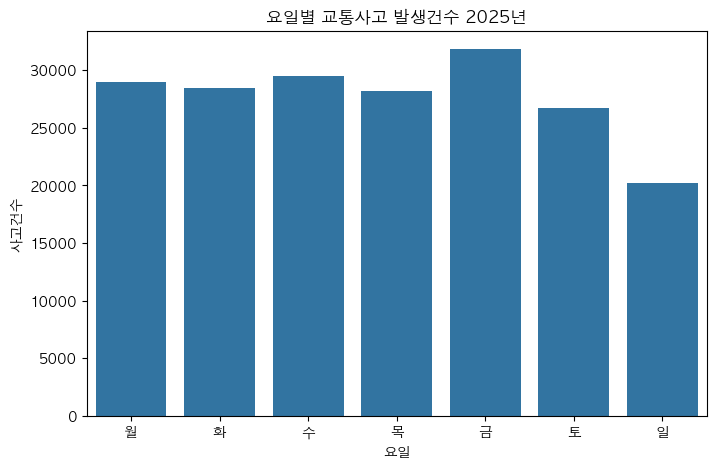

In [17]:
# 요일별 사고건수 합계
day_total = df_total.groupby('요일')['사고건수'].sum().reindex(
    ['월', '화', '수', '목', '금', '토', '일']
)

plt.figure(figsize=(8, 5))
sns.barplot(x=day_total.index, y=day_total.values)

plt.title('요일별 교통사고 발생건수 2025년')
plt.xlabel('요일')
plt.ylabel('사고건수')
plt.show()

### 2. 시간대별 교통사고 발생건수 Bar Chart

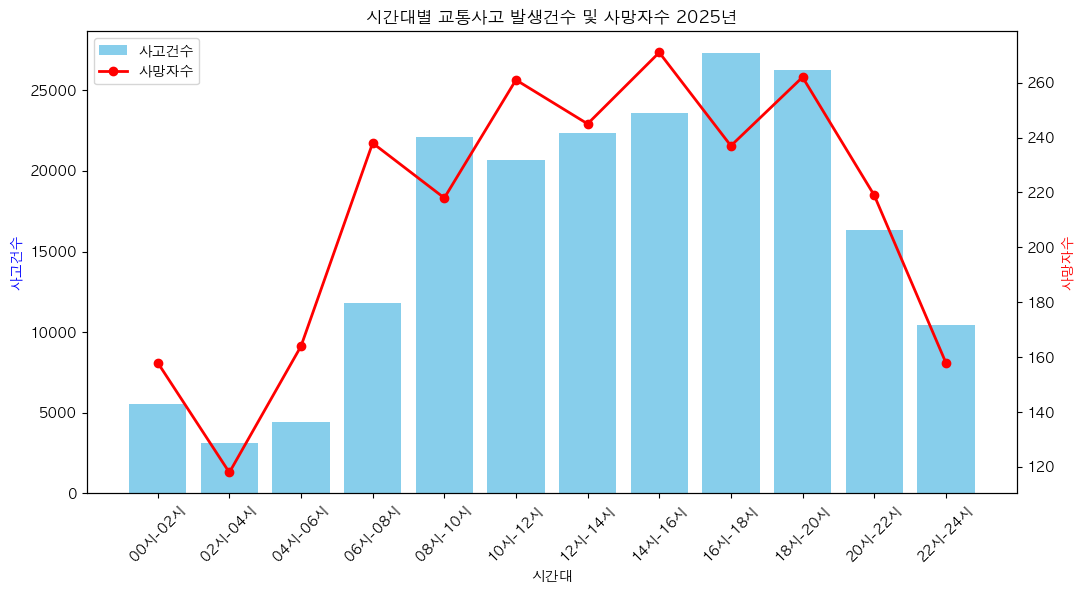

In [18]:
# 시간대별 사고건수와 사망자수 합계
time_total = df_total.groupby('시간대')[['사고건수', '사망자수']].sum()

# 그래프 생성
fig, ax1 = plt.subplots(figsize=(12, 6))

# 막대그래프: 사고건수 (파란색)
ax1.bar(time_total.index, time_total['사고건수'], color='skyblue', label='사고건수')
ax1.set_xlabel('시간대')
ax1.set_ylabel('사고건수', color='blue')

# 꺾은선그래프: 사망자수 (빨간색)
ax2 = ax1.twinx()
ax2.plot(time_total.index, time_total['사망자수'], color='red', marker='o', linewidth=2, label='사망자수')
ax2.set_ylabel('사망자수', color='red')

# 제목 및 범례
plt.title('시간대별 교통사고 발생건수 및 사망자수 2025년')
ax1.tick_params(axis='x', rotation=45)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.show()

### 3. 요일별·시간대별 교통사고 발생건수 Heatmap

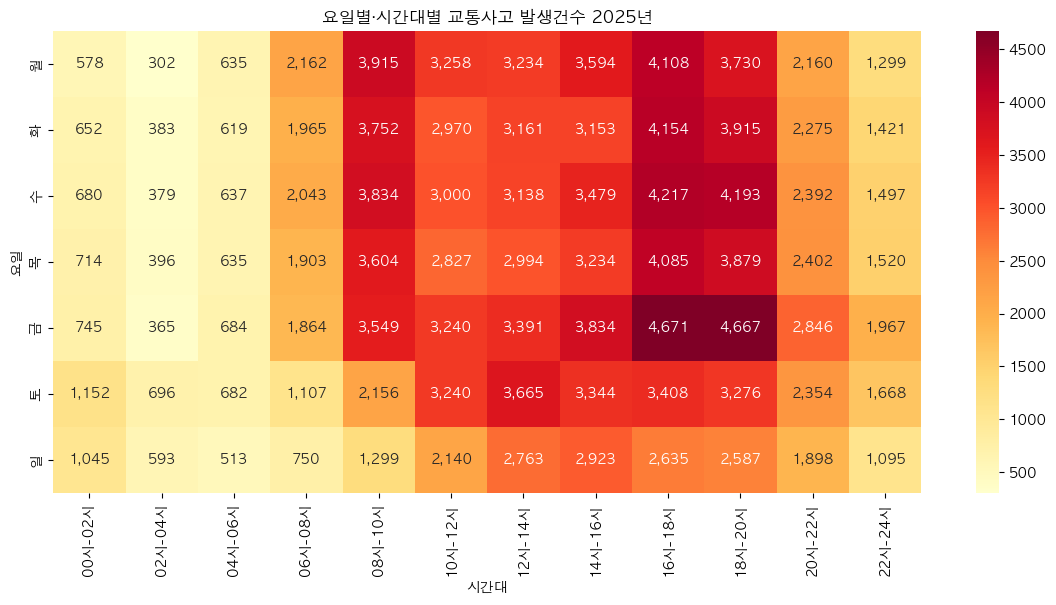

In [19]:
# 요일과 시간대별 사고건수 정리
heatmap_data = df_total.pivot_table(
    index='요일',
    columns='시간대',
    values='사고건수',
    aggfunc='sum'
)

# 요일 순서 정렬
heatmap_data = heatmap_data.reindex(
    ['월', '화', '수', '목', '금', '토', '일']
)

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_data, annot=True, fmt=',.0f', cmap='YlOrRd')

plt.title('요일별·시간대별 교통사고 발생건수 2025년')
plt.xlabel('시간대')
plt.ylabel('요일')
plt.show()